# Detector de dents impactades amb Faster R-CNN

Objectiu: passar de classificar tota l'ortopantomografia a predir directament les posicions de les dents impactades.

El model aprendrà una única classe clínica:

- `0`: background, reservat internament pel detector.
- `1`: dent impactada.

Les anotacions DENTEX tenen les boxes en format `[x, y, amplada, altura]`. Faster R-CNN necessita `[x_min, y_min, x_max, y_max]`, així que el dataset farà la conversió.

Aquest és un primer baseline: sense augmentacions, una sola classe i mètriques senzilles a IoU 0.5.

In [25]:
from pathlib import Path
from collections import defaultdict
import json
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Ti


In [ ]:
from pathlib import Path

project_paths = {
    "Training JSON": Path(
        "data/raw/dentex/training_data/"
        "quadrant-enumeration-disease/"
        "train_quadrant_enumeration_disease.json"
    ),

    "Training images": Path(
        "data/raw/dentex/training_data/"
        "quadrant-enumeration-disease/xrays"
    ),

    "Validation JSON": Path(
        "data/raw/dentex/validation_triple.json"
    ),

    "Validation images": Path(
        "data/raw/dentex/validation_data/"
        "quadrant_enumeration_disease/xrays"
    ),

    "Detector checkpoint": Path(
        "models/fasterrcnn_impacted_best.pt"
    ),

    "Results directory": Path(
        "results"
    )
}

for name, path in project_paths.items():
    print(
        f"{name:22} | "
        f"{'EXISTEIX' if path.exists() else 'NO EXISTEIX'} | "
        f"{path.resolve()}"
    )

Training JSON          | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\data\raw\dentex\training_data\quadrant-enumeration-disease\train_quadrant_enumeration_disease.json
Training images        | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\data\raw\dentex\training_data\quadrant-enumeration-disease\xrays
Validation JSON        | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\data\raw\dentex\validation_triple.json
Validation images      | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\data\raw\dentex\validation_data\quadrant_enumeration_disease\xrays
Detector checkpoint    | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\models\fasterrcnn_impacted_best.pt
Results directory      | EXISTEIX | C:\Users\Neo-PC\Desktop\rxDental\results


In [27]:
data_dir = Path("data/raw/dentex")

train_images_dir = (
    data_dir
    / "training_data"
    / "quadrant-enumeration-disease"
    / "xrays"
)

val_images_dir = (
    data_dir
    / "validation_data"
    / "quadrant_enumeration_disease"
    / "xrays"
)

train_json_path = (
    data_dir
    / "training_data"
    / "quadrant-enumeration-disease"
    / "train_quadrant_enumeration_disease.json"
)

val_json_path = data_dir / "validation_triple.json"

with open(train_json_path, "r") as file:
    train_data = json.load(file)

with open(val_json_path, "r") as file:
    val_data = json.load(file)


def find_diagnosis_id(data, diagnosis_name):
    """
    Busca l'id real al JSON en lloc de suposar que impacted sempre és 0.
    """
    diagnosis_name = diagnosis_name.lower()

    for category in data["categories_3"]:
        if diagnosis_name in category["name"].lower():
            return category["id"]

    raise ValueError(
        f"No s'ha trobat el diagnòstic: {diagnosis_name}"
    )


train_impacted_id = find_diagnosis_id(train_data, "impacted")
val_impacted_id = find_diagnosis_id(val_data, "impacted")

assert train_impacted_id == val_impacted_id
impacted_category_id = train_impacted_id

print("Train images:", len(train_data["images"]))
print("Validation images:", len(val_data["images"]))
print("ID de la categoria impacted:", impacted_category_id)
print("Categories de diagnòstic:", train_data["categories_3"])



Train images: 705
Validation images: 50
ID de la categoria impacted: 0
Categories de diagnòstic: [{'id': 0, 'name': 'Impacted', 'supercategory': 'Impacted'}, {'id': 1, 'name': 'Caries', 'supercategory': 'Caries'}, {'id': 2, 'name': 'Periapical Lesion', 'supercategory': 'Periapical Lesion'}, {'id': 3, 'name': 'Deep Caries', 'supercategory': 'Deep Caries'}]


In [28]:
class DentexImpactedDetectionDataset(Dataset):
    def __init__(
        self,
        data,
        images_dir,
        impacted_category_id
    ):
        self.images = data["images"]
        self.images_dir = Path(images_dir)
        self.impacted_category_id = impacted_category_id

        # Només guardem les anotacions de la categoria impacted
        # que hem identificat directament des de categories_3.
        self.impacted_annotations = defaultdict(list)

        for annotation in data["annotations"]:
            if (
                annotation["category_id_3"]
                == self.impacted_category_id
            ):
                self.impacted_annotations[
                    annotation["image_id"]
                ].append(annotation)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_info = self.images[index]
        image_id = image_info["id"]

        image_path = self.images_dir / image_info["file_name"]
        pil_image = Image.open(image_path).convert("RGB")

        image_width, image_height = pil_image.size

        # Tensor float en rang [0, 1].
        # Faster R-CNN farà internament la normalització i el resize.
        image = TF.pil_to_tensor(pil_image).float() / 255.0

        boxes = []

        for annotation in self.impacted_annotations.get(image_id, []):
            x, y, width, height = map(float, annotation["bbox"])

            # Format DENTEX xywh -> format Faster R-CNN xyxy.
            x_min = max(0.0, x)
            y_min = max(0.0, y)
            x_max = min(float(image_width), x + width)
            y_max = min(float(image_height), y + height)

            # Ignorem boxes degenerades, si n'hi hagués alguna.
            if x_max > x_min and y_max > y_min:
                boxes.append([x_min, y_min, x_max, y_max])

        if boxes:
            boxes = torch.tensor(boxes, dtype=torch.float32)
        else:
            boxes = torch.zeros((0, 4), dtype=torch.float32)

        # Totes les boxes que hem conservat són classe 1: impacted.
        labels = torch.ones(
            (boxes.shape[0],),
            dtype=torch.int64
        )

        area = (
            (boxes[:, 2] - boxes[:, 0])
            * (boxes[:, 3] - boxes[:, 1])
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([image_id]),
            "area": area,
            "iscrowd": torch.zeros(
                (boxes.shape[0],),
                dtype=torch.int64
            )
        }

        return image, target

    def file_name(self, index):
        return self.images[index]["file_name"]



In [29]:
train_dataset = DentexImpactedDetectionDataset(
    train_data,
    train_images_dir,
    impacted_category_id
)

val_dataset = DentexImpactedDetectionDataset(
    val_data,
    val_images_dir,
    impacted_category_id
)


def dataset_summary(dataset):
    boxes_per_image = [
        len(dataset.impacted_annotations.get(info["id"], []))
        for info in dataset.images
    ]

    return {
        "images": len(dataset),
        "positive_images": sum(n > 0 for n in boxes_per_image),
        "negative_images": sum(n == 0 for n in boxes_per_image),
        "impacted_boxes": sum(boxes_per_image)
    }


display(pd.DataFrame([
    {"split": "train", **dataset_summary(train_dataset)},
    {"split": "validation", **dataset_summary(val_dataset)}
]))

# Comprovacions bàsiques.
image, target = train_dataset[0]
print("Forma de la imatge:", image.shape)
print("Forma de boxes:", target["boxes"].shape)
print("Labels:", target["labels"])



,split,images,positive_images,negative_images,impacted_boxes
0,train,705,254,451,604
1,validation,50,16,34,40


Forma de la imatge: torch.Size([3, 1316, 2744])
Forma de boxes: torch.Size([2, 4])
Labels: tensor([1, 1])


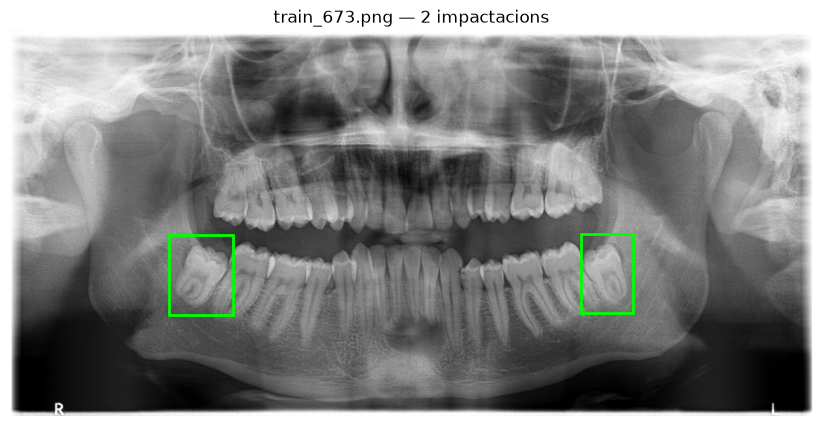

In [30]:
positive_index = next(
    index
    for index in range(len(train_dataset))
    if train_dataset[index][1]["boxes"].shape[0] > 0
)

image, target = train_dataset[positive_index]

figure, axis = plt.subplots(figsize=(16, 5))
axis.imshow(image.permute(1, 2, 0))

for x_min, y_min, x_max, y_max in target["boxes"]:
    axis.add_patch(
        Rectangle(
            (x_min.item(), y_min.item()),
            (x_max - x_min).item(),
            (y_max - y_min).item(),
            edgecolor="lime",
            facecolor="none",
            linewidth=2
        )
    )

axis.set_title(
    f"{train_dataset.file_name(positive_index)} — "
    f"{len(target['boxes'])} impactacions"
)
axis.axis("off")
plt.show()

In [31]:
def collate_fn(batch):
    # Les imatges poden tenir mides diferents i cada imatge
    # pot tenir un nombre diferent de boxes.
    return tuple(zip(*batch))


batch_size = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available()
)

images, targets = next(iter(train_loader))
print("Imatges al batch:", len(images))
print("Boxes per imatge:", [len(t["boxes"]) for t in targets])

Imatges al batch: 2
Boxes per imatge: [0, 0]


In [32]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


def build_detector(pretrained=True):
    if pretrained:
        model = fasterrcnn_resnet50_fpn(
            weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT,
            trainable_backbone_layers=3,
            min_size=512,
            max_size=1600
        )
    else:
        # Per reconstruir l'arquitectura abans de carregar el checkpoint.
        model = fasterrcnn_resnet50_fpn(
            weights=None,
            weights_backbone=None,
            min_size=512,
            max_size=1600
        )

    input_features = (
        model.roi_heads.box_predictor.cls_score.in_features
    )

    # Dues classes totals: background + impacted.
    model.roi_heads.box_predictor = FastRCNNPredictor(
        input_features,
        num_classes=2
    )

    return model


detector = build_detector(pretrained=True).to(device)
print("Detector creat.")

Detector creat.


In [33]:
# Smoke test: comprovem que una passada d'entrenament produeix losses.
images, targets = next(iter(train_loader))

images = [image.to(device) for image in images]
targets = [
    {key: value.to(device) for key, value in target.items()}
    for target in targets
]

detector.train()

with torch.no_grad():
    loss_dict = detector(images, targets)

print({
    name: round(value.item(), 4)
    for name, value in loss_dict.items()
})

detector.eval()

{'loss_classifier': 0.8049, 'loss_box_reg': 0.0, 'loss_objectness': 0.0066, 'loss_rpn_box_reg': 0.0}


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(512,), max_size=1600, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [34]:
def train_one_epoch(model, data_loader, optimizer, device):
    model.train()
    running_loss = 0.0
    n_images = 0

    for images, targets in data_loader:
        images = [image.to(device) for image in images]
        targets = [
            {key: value.to(device) for key, value in target.items()}
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        loss_dict = model(images, targets)
        total_loss = sum(loss_dict.values())

        if not torch.isfinite(total_loss):
            raise RuntimeError(
                f"Loss no finita: {total_loss.item()}"
            )

        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )
        optimizer.step()

        batch_images = len(images)
        running_loss += total_loss.item() * batch_images
        n_images += batch_images

    return running_loss / n_images

In [35]:
from torchvision.ops import box_iou


def match_image_detections(
    predicted_boxes,
    predicted_scores,
    true_boxes,
    score_threshold=0.30,
    iou_threshold=0.50
):
    keep = predicted_scores >= score_threshold
    predicted_boxes = predicted_boxes[keep]
    predicted_scores = predicted_scores[keep]

    # Ordenem de més a menys confiança.
    order = predicted_scores.argsort(descending=True)
    predicted_boxes = predicted_boxes[order]

    if len(predicted_boxes) == 0:
        return 0, 0, len(true_boxes)

    if len(true_boxes) == 0:
        return 0, len(predicted_boxes), 0

    ious = box_iou(predicted_boxes, true_boxes)
    matched_true_boxes = set()
    true_positives = 0
    false_positives = 0

    for prediction_index in range(len(predicted_boxes)):
        best_iou, true_index = ious[prediction_index].max(dim=0)
        true_index = true_index.item()

        if (
            best_iou.item() >= iou_threshold
            and true_index not in matched_true_boxes
        ):
            true_positives += 1
            matched_true_boxes.add(true_index)
        else:
            false_positives += 1

    false_negatives = len(true_boxes) - len(matched_true_boxes)

    return true_positives, false_positives, false_negatives


@torch.no_grad()
def evaluate_detector(
    model,
    data_loader,
    device,
    score_threshold=0.30,
    iou_threshold=0.50
):
    model.eval()

    total_tp = 0
    total_fp = 0
    total_fn = 0

    for images, targets in data_loader:
        images_device = [image.to(device) for image in images]
        outputs = model(images_device)

        for output, target in zip(outputs, targets):
            tp, fp, fn = match_image_detections(
                output["boxes"].cpu(),
                output["scores"].cpu(),
                target["boxes"],
                score_threshold=score_threshold,
                iou_threshold=iou_threshold
            )

            total_tp += tp
            total_fp += fp
            total_fn += fn

    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0
        else 0.0
    )

    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    return {
        "tp": total_tp,
        "fp": total_fp,
        "fn": total_fn,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [36]:
trainable_parameters = [
    parameter
    for parameter in detector.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.SGD(
    trainable_parameters,
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=3,
    gamma=0.1
)

num_epochs = 8
best_f1 = -1.0
checkpoint_path = Path(
    "models/fasterrcnn_impacted_best.pt"
)
checkpoint_path.parent.mkdir(exist_ok=True)

history = []

for epoch in range(num_epochs):
    train_loss = train_one_epoch(
        detector,
        train_loader,
        optimizer,
        device
    )

    validation_metrics = evaluate_detector(
        detector,
        val_loader,
        device,
        score_threshold=0.30,
        iou_threshold=0.50
    )

    scheduler.step()

    epoch_results = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **validation_metrics
    }
    history.append(epoch_results)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"precision: {validation_metrics['precision']:.3f} | "
        f"recall: {validation_metrics['recall']:.3f} | "
        f"F1: {validation_metrics['f1']:.3f} | "
        f"TP/FP/FN: {validation_metrics['tp']}/"
        f"{validation_metrics['fp']}/"
        f"{validation_metrics['fn']}"
    )

    if validation_metrics["f1"] > best_f1:
        best_f1 = validation_metrics["f1"]

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": detector.state_dict(),
                "metrics": validation_metrics
            },
            checkpoint_path
        )

        print(
            f"  Checkpoint desat amb F1={best_f1:.3f}"
        )

history_df = pd.DataFrame(history)
display(history_df)

Epoch 1/8 | train loss: 0.1282 | precision: 0.300 | recall: 0.975 | F1: 0.459 | TP/FP/FN: 39/91/1
  Checkpoint desat amb F1=0.459
Epoch 2/8 | train loss: 0.0861 | precision: 0.415 | recall: 0.975 | F1: 0.582 | TP/FP/FN: 39/55/1
  Checkpoint desat amb F1=0.582
Epoch 3/8 | train loss: 0.0688 | precision: 0.551 | recall: 0.950 | F1: 0.697 | TP/FP/FN: 38/31/2
  Checkpoint desat amb F1=0.697
Epoch 4/8 | train loss: 0.0502 | precision: 0.655 | recall: 0.900 | F1: 0.758 | TP/FP/FN: 36/19/4
  Checkpoint desat amb F1=0.758
Epoch 5/8 | train loss: 0.0460 | precision: 0.655 | recall: 0.900 | F1: 0.758 | TP/FP/FN: 36/19/4
Epoch 6/8 | train loss: 0.0426 | precision: 0.679 | recall: 0.900 | F1: 0.774 | TP/FP/FN: 36/17/4
  Checkpoint desat amb F1=0.774
Epoch 7/8 | train loss: 0.0400 | precision: 0.679 | recall: 0.900 | F1: 0.774 | TP/FP/FN: 36/17/4
Epoch 8/8 | train loss: 0.0392 | precision: 0.679 | recall: 0.900 | F1: 0.774 | TP/FP/FN: 36/17/4


,epoch,train_loss,tp,fp,fn,precision,recall,f1
0,1,0.128188,39,91,1,0.300000,0.975,0.458824
1,2,0.086134,39,55,1,0.414894,0.975,0.582090
2,3,0.068841,38,31,2,0.550725,0.950,0.697248
3,4,0.050200,36,19,4,0.654545,0.900,0.757895
4,5,0.046048,36,19,4,0.654545,0.900,0.757895
5,6,0.042642,36,17,4,0.679245,0.900,0.774194
6,7,0.040000,36,17,4,0.679245,0.900,0.774194
7,8,0.039213,36,17,4,0.679245,0.900,0.774194


In [37]:
best_detector = build_detector(pretrained=False).to(device)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

best_detector.load_state_dict(
    checkpoint["model_state_dict"]
)
best_detector.eval()

print("Millor època:", checkpoint["epoch"])
print("Mètriques desades:", checkpoint["metrics"])

Millor època: 6
Mètriques desades: {'tp': 36, 'fp': 17, 'fn': 4, 'precision': 0.6792452830188679, 'recall': 0.9, 'f1': 0.7741935483870968}


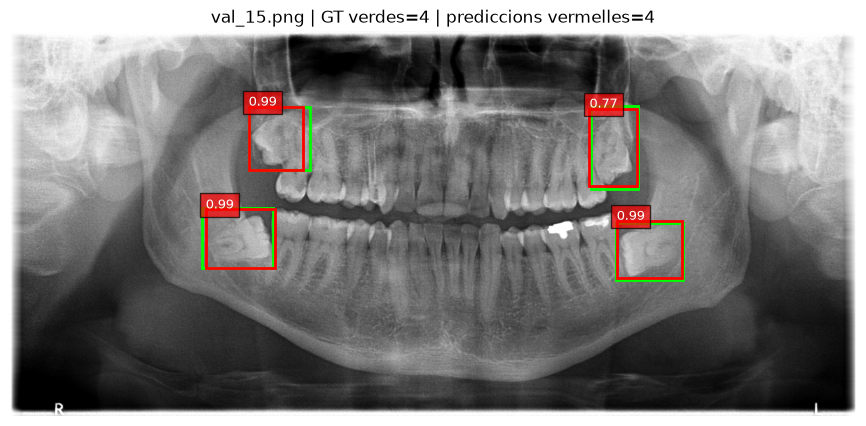

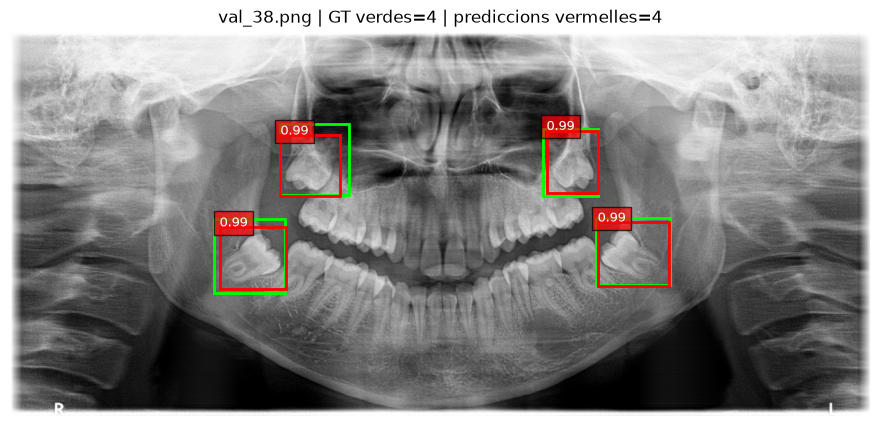

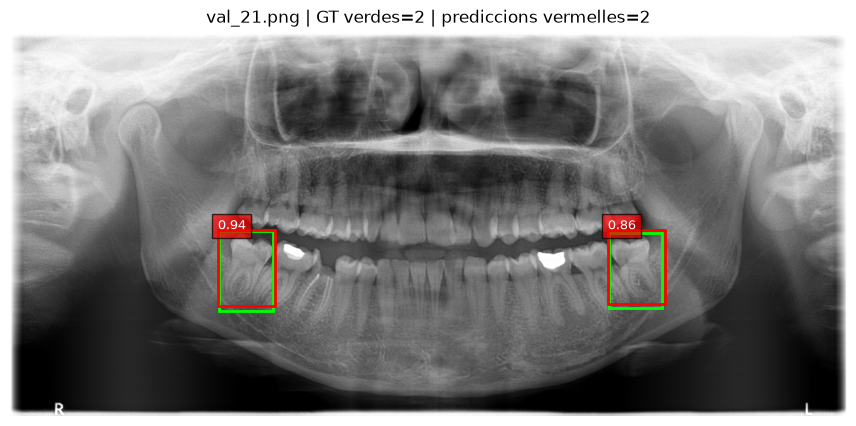

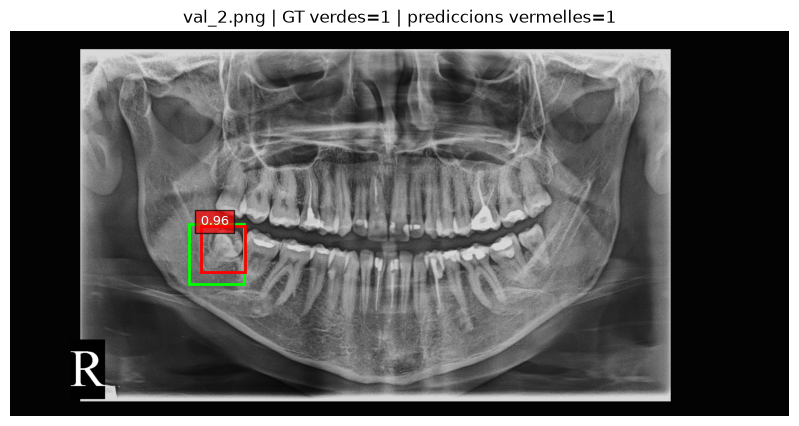

In [38]:
@torch.no_grad()
def show_detector_prediction(
    dataset,
    index,
    model=best_detector,
    score_threshold=0.30
):
    image, target = dataset[index]
    output = model([image.to(device)])[0]

    predicted_boxes = output["boxes"].cpu()
    predicted_scores = output["scores"].cpu()

    keep = predicted_scores >= score_threshold
    predicted_boxes = predicted_boxes[keep]
    predicted_scores = predicted_scores[keep]

    figure, axis = plt.subplots(figsize=(17, 5))
    axis.imshow(image.permute(1, 2, 0))

    # Ground truth en verd.
    for x_min, y_min, x_max, y_max in target["boxes"]:
        axis.add_patch(
            Rectangle(
                (x_min.item(), y_min.item()),
                (x_max - x_min).item(),
                (y_max - y_min).item(),
                edgecolor="lime",
                facecolor="none",
                linewidth=2
            )
        )

    # Prediccions en vermell.
    for box, score in zip(predicted_boxes, predicted_scores):
        x_min, y_min, x_max, y_max = box

        axis.add_patch(
            Rectangle(
                (x_min.item(), y_min.item()),
                (x_max - x_min).item(),
                (y_max - y_min).item(),
                edgecolor="red",
                facecolor="none",
                linewidth=2
            )
        )

        axis.text(
            x_min.item(),
            max(0, y_min.item() - 3),
            f"{score.item():.2f}",
            color="white",
            fontsize=9,
            bbox={"facecolor": "red", "alpha": 0.7}
        )

    axis.set_title(
        f"{dataset.file_name(index)} | "
        f"GT verdes={len(target['boxes'])} | "
        f"prediccions vermelles={len(predicted_boxes)}"
    )
    axis.axis("off")
    plt.show()


positive_indices = [
    index
    for index in range(len(val_dataset))
    if len(val_dataset[index][1]["boxes"]) > 0
][:4]

for index in positive_indices:
    show_detector_prediction(val_dataset, index)

In [39]:
# El llindar de score modifica el compromís precisió-recall.
threshold_results = []

for score_threshold in [0.20, 0.30, 0.50, 0.70]:
    metrics = evaluate_detector(
        best_detector,
        val_loader,
        device,
        score_threshold=score_threshold,
        iou_threshold=0.50
    )

    threshold_results.append({
        "score_threshold": score_threshold,
        **metrics
    })

display(pd.DataFrame(threshold_results))

,score_threshold,tp,fp,fn,precision,recall,f1
0,0.2,36,20,4,0.642857,0.900,0.750000
1,0.3,36,17,4,0.679245,0.900,0.774194
2,0.5,36,12,4,0.750000,0.900,0.818182
3,0.7,35,10,5,0.777778,0.875,0.823529


# I ara fem probes extra

In [50]:
# Configuració que congelarem per analitzar el baseline
ANALYSIS_SCORE_THRESHOLD = 0.50
ANALYSIS_IOU_THRESHOLD = 0.50


@torch.inference_mode()
def collect_validation_predictions(
    model,
    data_loader,
    dataset,
    device
):
    """
    Executa el model una sola vegada i guarda les prediccions
    i els ground truths a CPU.
    
    Important: el DataLoader ha de tenir shuffle=False.
    """
    model.eval()

    records = []
    dataset_index = 0

    for images, targets in data_loader:
        images_device = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        outputs = model(images_device)

        for output, target in zip(outputs, targets):
            # En aquest detector la classe 1 és "impacted".
            is_impacted = output["labels"] == 1

            records.append({
                "dataset_index": dataset_index,
                "file_name": dataset.file_name(dataset_index),
                "image_id": int(
                    target["image_id"].reshape(-1)[0].item()
                ),
                "pred_boxes": (
                    output["boxes"][is_impacted]
                    .detach()
                    .cpu()
                ),
                "pred_scores": (
                    output["scores"][is_impacted]
                    .detach()
                    .cpu()
                ),
                "gt_boxes": target["boxes"].detach().cpu()
            })

            dataset_index += 1

    if dataset_index != len(dataset):
        raise RuntimeError(
            f"S'han processat {dataset_index} imatges, "
            f"però el dataset en té {len(dataset)}."
        )

    return records


validation_predictions = collect_validation_predictions(
    best_detector,
    val_loader,
    val_dataset,
    device
)

print(
    "Imatges de validation processades:",
    len(validation_predictions)
)

Imatges de validation processades: 50


### Matrius de cofusio clares

In [51]:
def match_detections_with_details(
    record,
    score_threshold=0.70,
    iou_threshold=0.50
):
    all_pred_boxes = record["pred_boxes"]
    all_pred_scores = record["pred_scores"]
    gt_boxes = record["gt_boxes"]

    # Conservem només les prediccions per sobre del threshold.
    selected_indices = torch.where(
        all_pred_scores >= score_threshold
    )[0]

    # Les ordenem de major a menor confiança.
    if len(selected_indices) > 0:
        selected_order = torch.argsort(
            all_pred_scores[selected_indices],
            descending=True
        )
        selected_indices = selected_indices[selected_order]

    pred_boxes = all_pred_boxes[selected_indices]
    pred_scores = all_pred_scores[selected_indices]

    if len(pred_boxes) > 0 and len(gt_boxes) > 0:
        iou_matrix = box_iou(pred_boxes, gt_boxes)
    else:
        iou_matrix = torch.zeros(
            (len(pred_boxes), len(gt_boxes)),
            dtype=torch.float32
        )

    matched_gt_indices = set()
    matches = []
    false_positives = []

    # Mateix criteri que utilitzàvem a evaluate_detector.
    for pred_index in range(len(pred_boxes)):
        if len(gt_boxes) == 0:
            false_positives.append({
                "pred_index": pred_index,
                "original_pred_index": int(
                    selected_indices[pred_index]
                ),
                "score": float(pred_scores[pred_index]),
                "best_iou": 0.0,
                "reason": "sense cap GT a la imatge"
            })
            continue

        best_iou, gt_index_tensor = (
            iou_matrix[pred_index].max(dim=0)
        )

        best_iou = float(best_iou)
        gt_index = int(gt_index_tensor)

        if (
            best_iou >= iou_threshold
            and gt_index not in matched_gt_indices
        ):
            matched_gt_indices.add(gt_index)

            matches.append({
                "pred_index": pred_index,
                "original_pred_index": int(
                    selected_indices[pred_index]
                ),
                "gt_index": gt_index,
                "score": float(pred_scores[pred_index]),
                "iou": best_iou
            })

        else:
            if best_iou >= iou_threshold:
                reason = "possible detecció duplicada"
            elif best_iou >= 0.10:
                reason = "solapament insuficient"
            else:
                reason = "sense GT propera"

            false_positives.append({
                "pred_index": pred_index,
                "original_pred_index": int(
                    selected_indices[pred_index]
                ),
                "score": float(pred_scores[pred_index]),
                "best_iou": best_iou,
                "reason": reason
            })

    unmatched_gt_indices = [
        gt_index
        for gt_index in range(len(gt_boxes))
        if gt_index not in matched_gt_indices
    ]

    false_negatives = []

    for gt_index in unmatched_gt_indices:
        # Mirem també les prediccions sota el threshold.
        if len(all_pred_boxes) > 0:
            ious_with_gt = box_iou(
                all_pred_boxes,
                gt_boxes[gt_index].unsqueeze(0)
            ).squeeze(1)

            best_pred_index = int(
                torch.argmax(ious_with_gt)
            )

            best_iou_all = float(
                ious_with_gt[best_pred_index]
            )
            best_score_all = float(
                all_pred_scores[best_pred_index]
            )
        else:
            best_iou_all = 0.0
            best_score_all = float("nan")

        if (
            best_iou_all >= iou_threshold
            and best_score_all < score_threshold
        ):
            reason = "bona box, però score sota el threshold"
        elif best_iou_all >= iou_threshold:
            reason = "possible conflicte de matching"
        elif best_iou_all >= 0.10:
            reason = "box mal localitzada"
        else:
            reason = "cap proposta propera"

        false_negatives.append({
            "gt_index": gt_index,
            "best_iou_any_prediction": best_iou_all,
            "best_score_any_prediction": best_score_all,
            "reason": reason
        })

    return {
        "pred_boxes": pred_boxes,
        "pred_scores": pred_scores,
        "gt_boxes": gt_boxes,
        "matches": matches,
        "false_positives": false_positives,
        "false_negatives": false_negatives
    }

In [52]:
analysis_records = []

per_image_rows = []
match_rows = []
false_positive_rows = []
false_negative_rows = []

for record in validation_predictions:
    details = match_detections_with_details(
        record,
        score_threshold=ANALYSIS_SCORE_THRESHOLD,
        iou_threshold=ANALYSIS_IOU_THRESHOLD
    )

    analysis_record = {
        **record,
        "details": details
    }
    analysis_records.append(analysis_record)

    per_image_rows.append({
        "dataset_index": record["dataset_index"],
        "file_name": record["file_name"],
        "n_ground_truth": len(details["gt_boxes"]),
        "n_predictions": len(details["pred_boxes"]),
        "tp": len(details["matches"]),
        "fp": len(details["false_positives"]),
        "fn": len(details["false_negatives"])
    })

    for match in details["matches"]:
        match_rows.append({
            "dataset_index": record["dataset_index"],
            "file_name": record["file_name"],
            "score": match["score"],
            "iou": match["iou"],
            "pred_index": match["pred_index"],
            "gt_index": match["gt_index"]
        })

    for false_positive in details["false_positives"]:
        false_positive_rows.append({
            "dataset_index": record["dataset_index"],
            "file_name": record["file_name"],
            "score": false_positive["score"],
            "best_iou": false_positive["best_iou"],
            "reason": false_positive["reason"]
        })

    for false_negative in details["false_negatives"]:
        false_negative_rows.append({
            "dataset_index": record["dataset_index"],
            "file_name": record["file_name"],
            "best_iou_any_prediction": (
                false_negative["best_iou_any_prediction"]
            ),
            "best_score_any_prediction": (
                false_negative["best_score_any_prediction"]
            ),
            "reason": false_negative["reason"]
        })


per_image_df = pd.DataFrame(per_image_rows)
matches_df = pd.DataFrame(match_rows)
false_positives_df = pd.DataFrame(false_positive_rows)
false_negatives_df = pd.DataFrame(false_negative_rows)

total_tp = int(per_image_df["tp"].sum())
total_fp = int(per_image_df["fp"].sum())
total_fn = int(per_image_df["fn"].sum())

precision = total_tp / (total_tp + total_fp)
recall = total_tp / (total_tp + total_fn)
f1 = 2 * precision * recall / (precision + recall)

summary_df = pd.DataFrame([{
    "score_threshold": ANALYSIS_SCORE_THRESHOLD,
    "iou_threshold": ANALYSIS_IOU_THRESHOLD,
    "tp": total_tp,
    "fp": total_fp,
    "fn": total_fn,
    "precision": precision,
    "recall": recall,
    "f1": f1
}])

display(summary_df)

,score_threshold,iou_threshold,tp,fp,fn,precision,recall,f1
0,0.5,0.5,36,12,4,0.75,0.9,0.818182


In [53]:
error_images_df = per_image_df[
    (per_image_df["fp"] > 0)
    | (per_image_df["fn"] > 0)
].copy()

error_images_df = error_images_df.sort_values(
    ["fn", "fp"],
    ascending=False
)

print("Imatges amb almenys un error:")
display(error_images_df)

print("\nFalsos positius:")
display(
    false_positives_df
    .sort_values("score", ascending=False)
    .reset_index(drop=True)
)

print("\nFalsos negatius:")
display(
    false_negatives_df
    .sort_values(
        "best_iou_any_prediction",
        ascending=False
    )
    .reset_index(drop=True)
)

Imatges amb almenys un error:


,dataset_index,file_name,n_ground_truth,n_predictions,tp,fp,fn
19,19,val_41.png,2,0,0,0,2
40,40,val_9.png,2,1,1,0,1
49,49,val_0.png,1,0,0,0,1
24,24,val_13.png,0,5,0,5,0
41,41,val_4.png,0,4,0,4,0
26,26,val_49.png,0,1,0,1,0
46,46,val_12.png,1,2,1,1,0
47,47,val_7.png,2,3,2,1,0



Falsos positius:


,dataset_index,file_name,score,best_iou,reason
0,24,val_13.png,0.993881,0.0,sense cap GT a la imatge
1,41,val_4.png,0.993108,0.0,sense cap GT a la imatge
2,41,val_4.png,0.991843,0.0,sense cap GT a la imatge
3,41,val_4.png,0.990598,0.0,sense cap GT a la imatge
4,24,val_13.png,0.989376,0.0,sense cap GT a la imatge
5,24,val_13.png,0.986824,0.0,sense cap GT a la imatge
6,41,val_4.png,0.983143,0.0,sense cap GT a la imatge
7,26,val_49.png,0.970165,0.0,sense cap GT a la imatge
8,24,val_13.png,0.931129,0.0,sense cap GT a la imatge
9,47,val_7.png,0.854369,0.0,sense GT propera



Falsos negatius:


,dataset_index,file_name,best_iou_any_prediction,best_score_any_prediction,reason
0,40,val_9.png,0.777651,0.081376,"bona box, però score sota el threshold"
1,19,val_41.png,0.024290,0.072161,cap proposta propera
2,19,val_41.png,0.000000,0.072161,cap proposta propera
3,49,val_0.png,0.000000,0.064057,cap proposta propera


## Galeria d'errors

Imatges amb errors: 8


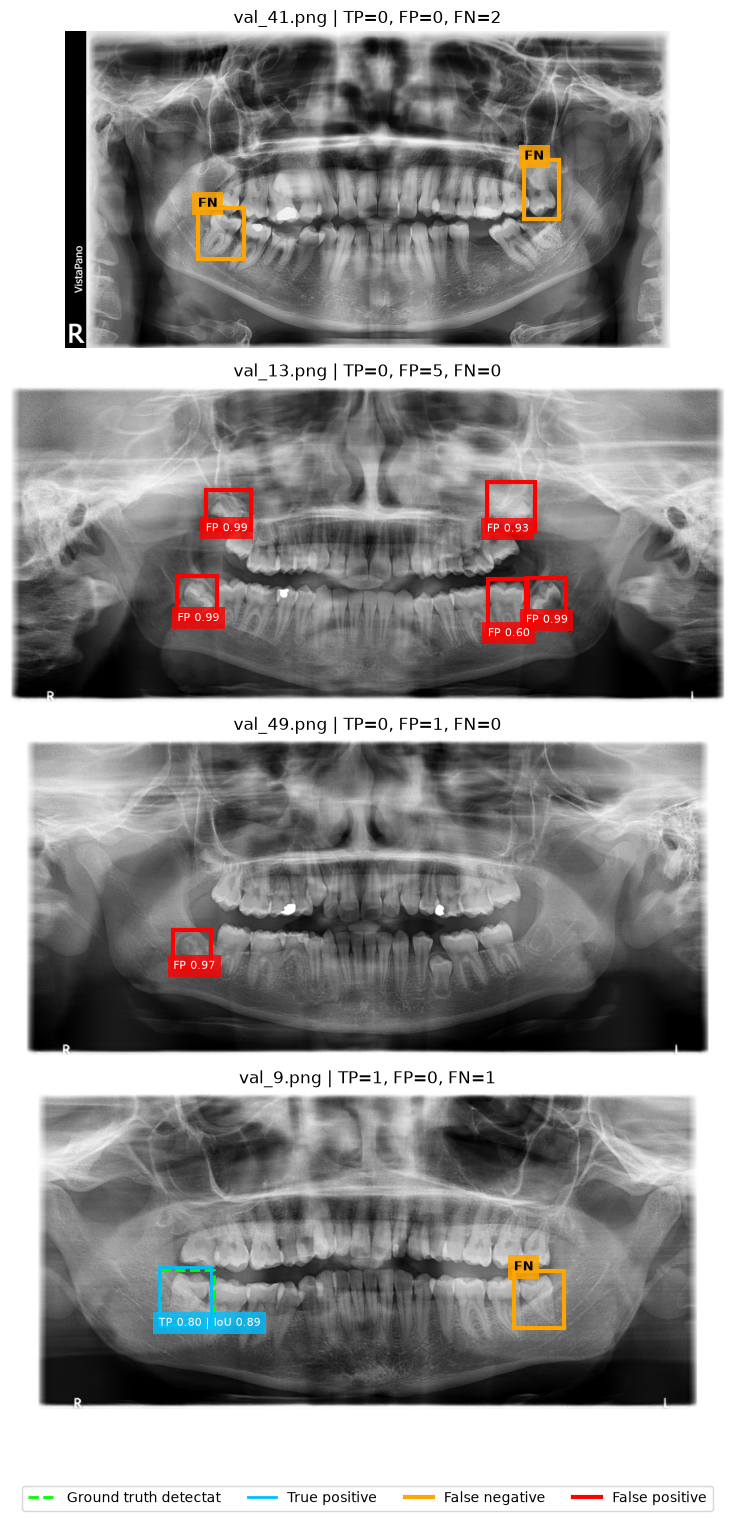

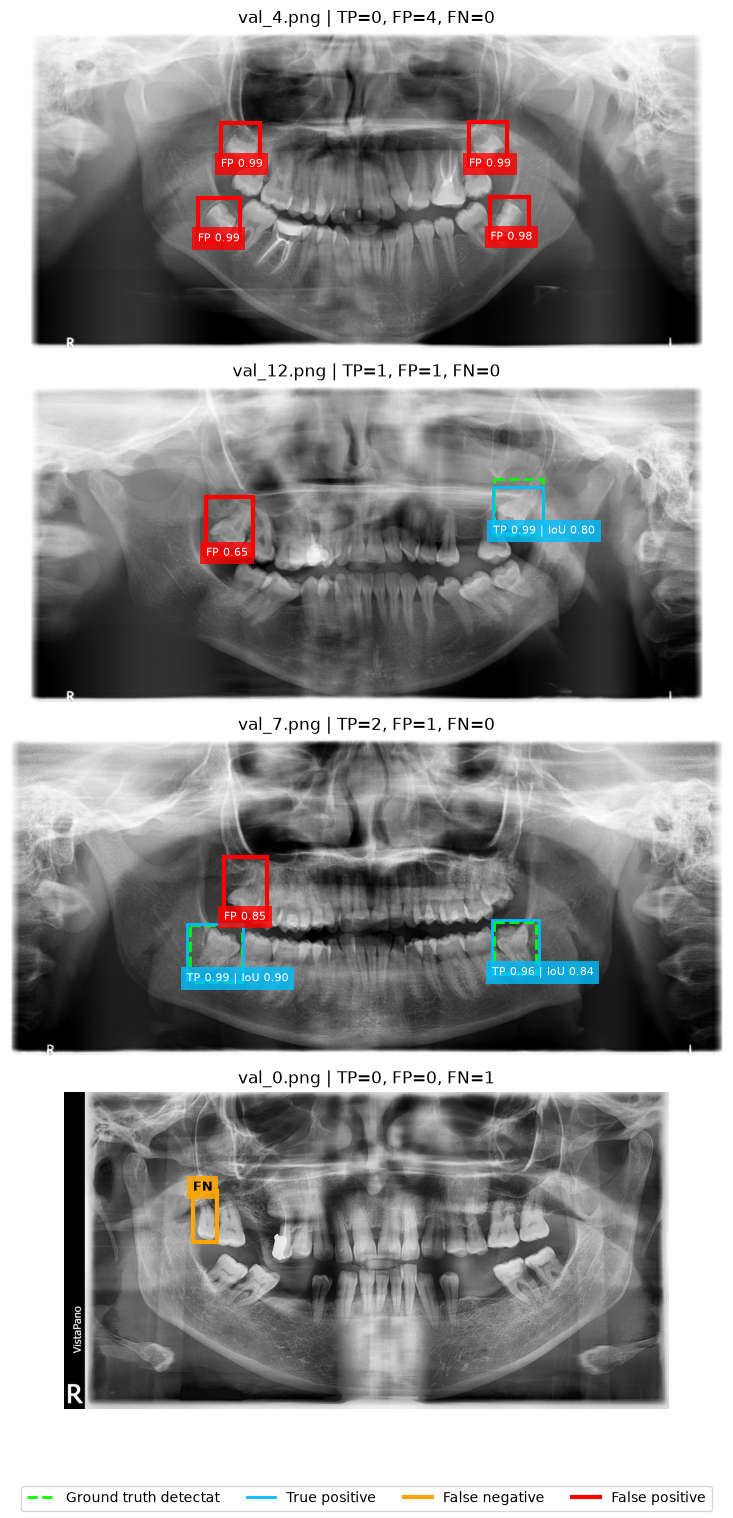

In [54]:
from matplotlib.lines import Line2D


def draw_detection_box(
    axis,
    box,
    color,
    linewidth=2,
    linestyle="-"
):
    x_min, y_min, x_max, y_max = [
        float(value)
        for value in box
    ]

    axis.add_patch(
        Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            edgecolor=color,
            facecolor="none",
            linewidth=linewidth,
            linestyle=linestyle
        )
    )


def draw_error_image(axis, record, dataset):
    image, _ = dataset[record["dataset_index"]]
    details = record["details"]

    axis.imshow(image.permute(1, 2, 0).numpy())

    false_negative_indices = {
        error["gt_index"]
        for error in details["false_negatives"]
    }

    false_positive_indices = {
        error["pred_index"]
        for error in details["false_positives"]
    }

    matches_by_prediction = {
        match["pred_index"]: match
        for match in details["matches"]
    }

    # Ground truths.
    for gt_index, gt_box in enumerate(details["gt_boxes"]):
        if gt_index in false_negative_indices:
            color = "orange"
            linewidth = 3
            linestyle = "-"
        else:
            color = "lime"
            linewidth = 2
            linestyle = "--"

        draw_detection_box(
            axis,
            gt_box,
            color=color,
            linewidth=linewidth,
            linestyle=linestyle
        )

        if gt_index in false_negative_indices:
            x_min = float(gt_box[0])
            y_min = float(gt_box[1])

            axis.text(
                x_min,
                max(0, y_min - 4),
                "FN",
                color="black",
                fontsize=9,
                fontweight="bold",
                bbox={
                    "facecolor": "orange",
                    "alpha": 0.85,
                    "edgecolor": "none"
                }
            )

    # Prediccions conservades amb threshold 0.7.
    for pred_index, (pred_box, score) in enumerate(
        zip(
            details["pred_boxes"],
            details["pred_scores"]
        )
    ):
        if pred_index in false_positive_indices:
            color = "red"
            label = f"FP {float(score):.2f}"
            linewidth = 3
        else:
            color = "deepskyblue"
            match = matches_by_prediction[pred_index]
            label = (
                f"TP {float(score):.2f} | "
                f"IoU {match['iou']:.2f}"
            )
            linewidth = 2

        draw_detection_box(
            axis,
            pred_box,
            color=color,
            linewidth=linewidth
        )

        x_min = float(pred_box[0])
        y_max = float(pred_box[3])

        axis.text(
            x_min,
            y_max + 3,
            label,
            color="white",
            fontsize=8,
            bbox={
                "facecolor": color,
                "alpha": 0.80,
                "edgecolor": "none"
            }
        )

    axis.set_title(
        f"{record['file_name']} | "
        f"TP={len(details['matches'])}, "
        f"FP={len(details['false_positives'])}, "
        f"FN={len(details['false_negatives'])}"
    )

    axis.axis("off")


def show_error_gallery(
    analysis_records,
    dataset,
    images_per_page=4
):
    records_with_errors = [
        record
        for record in analysis_records
        if (
            len(record["details"]["false_positives"]) > 0
            or len(record["details"]["false_negatives"]) > 0
        )
    ]

    print(
        "Imatges amb errors:",
        len(records_with_errors)
    )

    legend_handles = [
        Line2D(
            [0], [0],
            color="lime",
            linestyle="--",
            linewidth=2,
            label="Ground truth detectat"
        ),
        Line2D(
            [0], [0],
            color="deepskyblue",
            linewidth=2,
            label="True positive"
        ),
        Line2D(
            [0], [0],
            color="orange",
            linewidth=3,
            label="False negative"
        ),
        Line2D(
            [0], [0],
            color="red",
            linewidth=3,
            label="False positive"
        )
    ]

    for start in range(
        0,
        len(records_with_errors),
        images_per_page
    ):
        page_records = records_with_errors[
            start:start + images_per_page
        ]

        figure, axes = plt.subplots(
            len(page_records),
            1,
            figsize=(18, 3.8 * len(page_records)),
            squeeze=False
        )

        for axis, record in zip(
            axes[:, 0],
            page_records
        ):
            draw_error_image(
                axis,
                record,
                dataset
            )

        figure.legend(
            handles=legend_handles,
            loc="lower center",
            ncol=4
        )

        figure.tight_layout(
            rect=(0, 0.06, 1, 1)
        )
        plt.show()


show_error_gallery(
    analysis_records,
    val_dataset,
    images_per_page=4
)

#### Distribució d'IOU's

,n_true_positives,mean_iou,median_iou,q25_iou,q75_iou,min_iou,max_iou
0,36,0.835,0.856,0.786,0.889,0.593,0.966


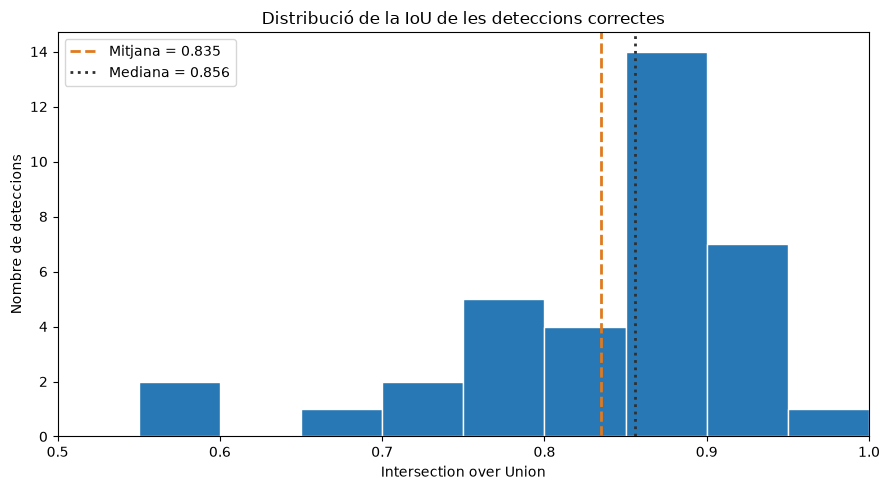

In [55]:
iou_summary_df = pd.DataFrame([{
    "n_true_positives": len(matches_df),
    "mean_iou": matches_df["iou"].mean(),
    "median_iou": matches_df["iou"].median(),
    "q25_iou": matches_df["iou"].quantile(0.25),
    "q75_iou": matches_df["iou"].quantile(0.75),
    "min_iou": matches_df["iou"].min(),
    "max_iou": matches_df["iou"].max()
}])

display(iou_summary_df.round(3))


figure, axis = plt.subplots(figsize=(9, 5))

bins = np.linspace(
    ANALYSIS_IOU_THRESHOLD,
    1.0,
    11
)

axis.hist(
    matches_df["iou"],
    bins=bins,
    color="#2878B5",
    edgecolor="white"
)

mean_iou = matches_df["iou"].mean()
median_iou = matches_df["iou"].median()

axis.axvline(
    mean_iou,
    color="#E07A1F",
    linestyle="--",
    linewidth=2,
    label=f"Mitjana = {mean_iou:.3f}"
)

axis.axvline(
    median_iou,
    color="#303030",
    linestyle=":",
    linewidth=2,
    label=f"Mediana = {median_iou:.3f}"
)

axis.set_title(
    "Distribució de la IoU de les deteccions correctes"
)
axis.set_xlabel("Intersection over Union")
axis.set_ylabel("Nombre de deteccions")
axis.set_xlim(0.50, 1.00)
axis.legend()

plt.tight_layout()
plt.show()

# AP 50 i mAP50-95 (ni idea k es això)

In [56]:
def compute_ap_at_iou(
    prediction_records,
    iou_threshold,
    max_detections_per_image=100
):
    """
    AP per a una classe utilitzant interpolació de 101 punts.
    """

    ground_truths_by_image = {}
    detections = []
    total_ground_truths = 0

    for record in prediction_records:
        image_index = record["dataset_index"]
        gt_boxes = record["gt_boxes"]

        ground_truths_by_image[image_index] = gt_boxes
        total_ground_truths += len(gt_boxes)

        scores = record["pred_scores"]
        boxes = record["pred_boxes"]

        order = torch.argsort(
            scores,
            descending=True
        )[:max_detections_per_image]

        for pred_index in order:
            detections.append({
                "image_index": image_index,
                "score": float(scores[pred_index]),
                "box": boxes[pred_index]
            })

    if total_ground_truths == 0:
        raise ValueError(
            "No hi ha ground truths per calcular AP."
        )

    # Ordenació global de totes les prediccions.
    detections = sorted(
        detections,
        key=lambda detection: detection["score"],
        reverse=True
    )

    matched_gt_by_image = {
        image_index: set()
        for image_index in ground_truths_by_image
    }

    true_positives = []
    false_positives = []
    detection_scores = []

    for detection in detections:
        image_index = detection["image_index"]
        predicted_box = detection["box"]
        gt_boxes = ground_truths_by_image[image_index]

        detection_scores.append(detection["score"])

        if len(gt_boxes) == 0:
            true_positives.append(0)
            false_positives.append(1)
            continue

        ious = box_iou(
            predicted_box.unsqueeze(0),
            gt_boxes
        ).squeeze(0)

        # No permetem tornar a assignar una GT ja utilitzada.
        for matched_index in matched_gt_by_image[image_index]:
            ious[matched_index] = -1.0

        best_iou, gt_index_tensor = ious.max(dim=0)

        best_iou = float(best_iou)
        gt_index = int(gt_index_tensor)

        if best_iou >= iou_threshold:
            true_positives.append(1)
            false_positives.append(0)
            matched_gt_by_image[image_index].add(gt_index)
        else:
            true_positives.append(0)
            false_positives.append(1)

    if len(detections) == 0:
        empty_curve = pd.DataFrame(
            columns=[
                "score",
                "recall",
                "precision",
                "precision_envelope"
            ]
        )
        return 0.0, empty_curve

    cumulative_tp = np.cumsum(
        np.asarray(true_positives, dtype=float)
    )
    cumulative_fp = np.cumsum(
        np.asarray(false_positives, dtype=float)
    )

    recall = cumulative_tp / total_ground_truths

    precision = cumulative_tp / np.maximum(
        cumulative_tp + cumulative_fp,
        1e-12
    )

    # Fa que la precisió sigui monòtona.
    precision_envelope = np.maximum.accumulate(
        precision[::-1]
    )[::-1]

    recall_levels = np.linspace(0, 1, 101)

    interpolated_precision = []

    for recall_level in recall_levels:
        valid_positions = recall >= recall_level

        if np.any(valid_positions):
            interpolated_precision.append(
                precision_envelope[
                    valid_positions
                ].max()
            )
        else:
            interpolated_precision.append(0.0)

    average_precision = float(
        np.mean(interpolated_precision)
    )

    curve_df = pd.DataFrame({
        "score": detection_scores,
        "recall": recall,
        "precision": precision,
        "precision_envelope": precision_envelope
    })

    return average_precision, curve_df

In [57]:
iou_thresholds = np.round(
    np.arange(0.50, 1.00, 0.05),
    2
)

ap_rows = []
pr_curve_at_50 = None

for iou_threshold in iou_thresholds:
    average_precision, curve_df = compute_ap_at_iou(
        validation_predictions,
        iou_threshold=iou_threshold
    )

    ap_rows.append({
        "iou_threshold": iou_threshold,
        "average_precision": average_precision
    })

    if np.isclose(iou_threshold, 0.50):
        pr_curve_at_50 = curve_df


ap_by_iou_df = pd.DataFrame(ap_rows)

ap50 = float(
    ap_by_iou_df.loc[
        np.isclose(
            ap_by_iou_df["iou_threshold"],
            0.50
        ),
        "average_precision"
    ].iloc[0]
)

map_50_95 = float(
    ap_by_iou_df["average_precision"].mean()
)

standard_metrics_df = pd.DataFrame([{
    "AP50": ap50,
    "mAP50_95": map_50_95,
    "n_ground_truth_boxes": sum(
        len(record["gt_boxes"])
        for record in validation_predictions
    )
}])

display(standard_metrics_df.round(4))
display(ap_by_iou_df.round(4))

,AP50,mAP50_95,n_ground_truth_boxes
0,0.7297,0.4676,40


,iou_threshold,average_precision
0,0.50,0.7297
1,0.55,0.7297
2,0.60,0.6619
3,0.65,0.6619
4,0.70,0.6312
5,0.75,0.5483
6,0.80,0.3776
7,0.85,0.2717
8,0.90,0.0622
9,0.95,0.0016


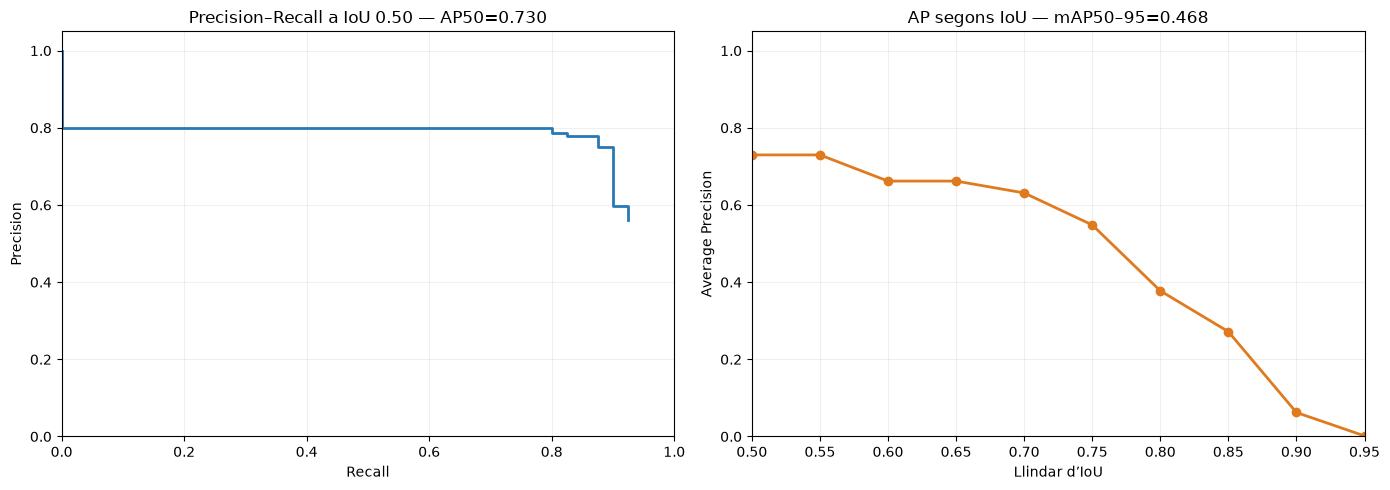

In [58]:
figure, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# Corba precision-recall a IoU 0.50.
axes[0].step(
    np.concatenate([
        [0.0],
        pr_curve_at_50["recall"].to_numpy()
    ]),
    np.concatenate([
        [1.0],
        pr_curve_at_50[
            "precision_envelope"
        ].to_numpy()
    ]),
    where="post",
    color="#2878B5",
    linewidth=2
)

axes[0].set_title(
    f"Precision–Recall a IoU 0.50 — AP50={ap50:.3f}"
)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1.05)
axes[0].grid(alpha=0.2)

# Com cau l'AP quan demanem boxes més precises.
axes[1].plot(
    ap_by_iou_df["iou_threshold"],
    ap_by_iou_df["average_precision"],
    marker="o",
    color="#E07A1F",
    linewidth=2
)

axes[1].set_title(
    f"AP segons IoU — mAP50–95={map_50_95:.3f}"
)
axes[1].set_xlabel("Llindar d’IoU")
axes[1].set_ylabel("Average Precision")
axes[1].set_xlim(0.50, 0.95)
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Guardem resultats

In [59]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

summary_df.to_csv(
    results_dir / "baseline_summary.csv",
    index=False
)

per_image_df.to_csv(
    results_dir / "per_image_detection_results.csv",
    index=False
)

matches_df.to_csv(
    results_dir / "matched_detections.csv",
    index=False
)

false_positives_df.to_csv(
    results_dir / "false_positives.csv",
    index=False
)

false_negatives_df.to_csv(
    results_dir / "false_negatives.csv",
    index=False
)

ap_by_iou_df.to_csv(
    results_dir / "average_precision_by_iou.csv",
    index=False
)

baseline_config = {
    "checkpoint": str(checkpoint_path),
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "score_threshold": ANALYSIS_SCORE_THRESHOLD,
    "matching_iou_threshold": ANALYSIS_IOU_THRESHOLD,
    "detector": "Faster R-CNN ResNet50 FPN",
    "target_class": "impacted",
    "validation_images": len(val_dataset)
}

with open(
    results_dir / "baseline_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        baseline_config,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Resultats guardats a:", results_dir.resolve())

Resultats guardats a: C:\Users\Neo-PC\Desktop\rxDental\results
